# World population by region

How has the world's population changed since 1990? This notebook uses a
[World Bank snapshot](https://data.worldbank.org/indicator/SP.POP.TOTL) to
compare growth across regions. The annual population totals from 1990 through
2025 are bundled in `world_population.csv`, so the notebook runs offline.

Source data is from World Development Indicators, updated November 11, 2026,
and licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
The CSV uses the region labels in the
[World Bank download](https://api.worldbank.org/v2/en/indicator/SP.POP.TOTL?downloadformat=csv).

To rebuild the CSV from the bundled source, run
`pixi run python tools/update_world_population.py` from the repository root.
To refresh from a newer World Bank download, pass its ZIP file as an argument.

The notebook is paired with Percent, Light, Markdown, R Markdown, and MyST.
The Sphinx Gallery and Pandoc files are standalone exports. Install
`pandas` and `matplotlib` to run the analysis and static chart locally.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

population = pd.read_csv("world_population.csv", index_col="year")
latest = population.iloc[-1]
print(f"{latest.name}: {latest['World'] / 1e9:.2f} billion people worldwide.")
population[["World"]].tail()

2025: 8.22 billion people worldwide.


,World
year,
2021,7919567995
2022,7988550201
2023,8062923417
2024,8140897523
2025,8215424893


## Population across regions

The World Bank supplies a separate world total. The charts use the seven
reported regional series and express their populations in billions.

In [2]:
regions = population.drop(columns="World").div(1e9)
regions = regions[regions.iloc[-1].sort_values(ascending=False).index]

The stacked area chart shows how the contribution of each region changes over
time.

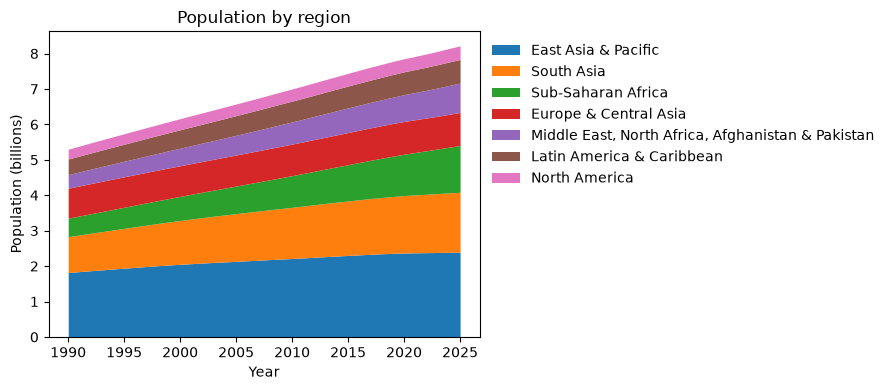

In [3]:
ax = regions.plot.area(figsize=(9, 4), linewidth=0)
ax.set(xlabel="Year", ylabel="Population (billions)", title="Population by region")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
ax.figure.tight_layout()
plt.show()

## Optional interactive chart

With `plotly` installed, run this cell in JupyterLab. Hover for the
population of a region in a given year, or click a region in the legend
to hide it.

In [4]:
import plotly.express as px

px.area(
    regions,
    labels={"year": "Year", "value": "Population (billions)", "variable": "Region"},
    title="Population by region",
)